# Exploratory Data Analysis (EDA) – AI4I 2020 Predictive Maintenance

## Objective
Explore distributions, relationships, and differences between failure and non-failure cases to identify potential data quality issues and candidate drivers of machine failure.


In [1]:
# Import core data manipulation libraries
import pandas as pd
import numpy as np

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import system utilities for handling project paths
import sys
from pathlib import Path

# Set default plotting size for consistent visualizations
plt.rcParams["figure.figsize"] = (8, 5)

# Define project root directory
PROJECT_ROOT = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / "src" / "data_loader.py").is_file() and (p / "data").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this project's folder in VS Code before running the notebook.")
for _path in (PROJECT_ROOT, PROJECT_ROOT / "src"):
    if str(_path) not in sys.path:
        sys.path.insert(0, str(_path))

# Add the src folder to the system path so custom modules can be imported
sys.path.append(str(PROJECT_ROOT / "src"))

# Import reusable project functions
from data_loader import load_raw_data
from features import add_engineered_features

# Load the cleaned dataset
df = load_raw_data()

# Apply feature engineering functions
# This adds derived variables used later in modeling
df = add_engineered_features(df)

# Preview the dataset to verify that data loaded and features were added
df.head()

Out[1]: 
   UDI Product ID Type  ...  RNF  Temp_diff  Torque_RPM_ratio
0    1     M14860    M  ...    0       10.5          0.027577
1    2     L47181    L  ...    0       10.5          0.032860
2    3     L47182    L  ...    0       10.4          0.032955
3    4     L47183    L  ...    0       10.4          0.027545
4    5     L47184    L  ...    0       10.5          0.028389

[5 rows x 16 columns]


## Dataset Overview

Before performing deeper analysis, we first inspect the structure of the dataset.  
This includes examining the number of observations, number of variables, column names, and data types.

This step ensures that the dataset has been loaded correctly and that the engineered features are present.

In [2]:
# Display dataset shape
print("Dataset shape:", df.shape)

# Display column names
print("\nColumns in dataset:")
print(df.columns.tolist())

# Display dataset information including data types
print("\nDataset info:")
df.info()

Dataset shape: (10000, 16)

Columns in dataset:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF', 'Temp_diff', 'Torque_RPM_ratio']

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF

## Descriptive Statistics

In this section, we examine summary statistics of the dataset.  
This helps understand the distribution and scale of numerical variables such as temperature, rotational speed, torque, and tool wear.

Key metrics include:
- Mean
- Standard deviation
- Minimum and maximum values
- Quartiles

These statistics help detect unusual values and understand how sensor readings vary across machines.

In [3]:
# Generate summary statistics for numerical columns
df.describe()

Out[3]: 
               UDI  Air temperature [K]  ...     Temp_diff  Torque_RPM_ratio
count  10000.00000         10000.000000  ...  10000.000000      10000.000000
mean    5000.50000           300.004930  ...     10.000630          0.026877
std     2886.89568             2.000259  ...      1.001094          0.008831
min        1.00000           295.300000  ...      7.600000          0.001316
25%     2500.75000           298.300000  ...      9.300000          0.020627
50%     5000.50000           300.100000  ...      9.800000          0.026718
75%     7500.25000           301.500000  ...     11.000000          0.032782
max    10000.00000           304.500000  ...     12.100000          0.063780

[8 rows x 14 columns]


## Missing Values Analysis

Before performing deeper analysis, it is important to check whether the dataset contains missing values.  
Missing data can negatively affect model performance and may require imputation or removal.

This section examines the presence of null values across all variables in the dataset.

In [4]:
# Check for missing values in each column
missing_values = df.isnull().sum()

# Display columns that contain missing values
missing_values[missing_values > 0]

Out[4]: Series([], dtype: int64)


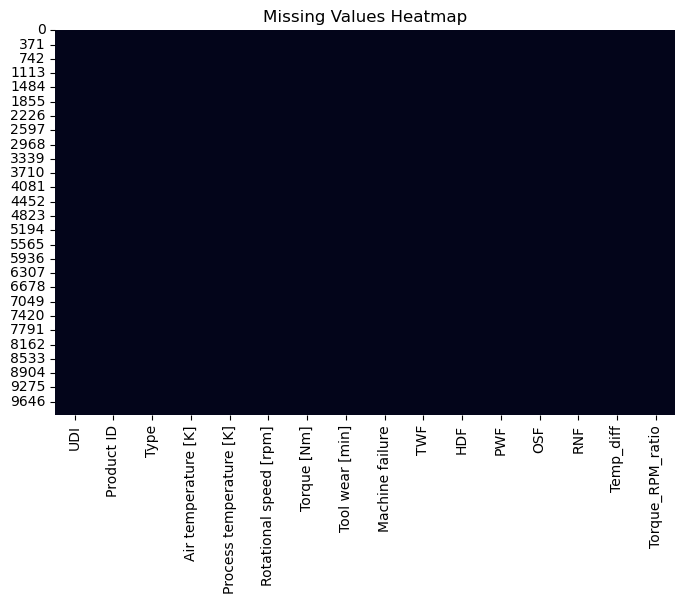

In [5]:
# Visualize missing values using a heatmap

plt.figure()
sns.heatmap(df.isnull(), cbar=False)

plt.title("Missing Values Heatmap")

# Save the visualization
plt.savefig(PROJECT_ROOT / "visuals" / "missing_values_heatmap.png", bbox_inches="tight")

plt.show()

## Target Variable Analysis

In this section, we analyze the distribution of the target variable **Machine failure**.  
Understanding the balance between failure and non-failure cases is important for classification modeling.

If the dataset is highly imbalanced, special techniques such as class weighting or resampling may be required during model training.

In [6]:
# Count the number of observations for each class in the target variable
df["Machine failure"].value_counts()

Out[6]: 
Machine failure
0    9661
1     339
Name: count, dtype: int64


In [7]:
# Display percentage distribution of the target variable
df["Machine failure"].value_counts(normalize=True) * 100

Out[7]: 
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


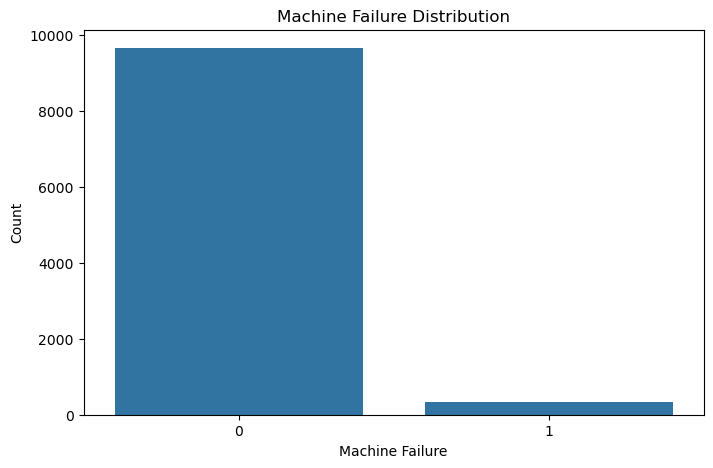

In [8]:
# Visualize the distribution of machine failure

plt.figure()

sns.countplot(x="Machine failure", data=df)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure")
plt.ylabel("Count")

# Save visualization
plt.savefig(PROJECT_ROOT / "visuals" / "machine_failure_distribution.png", bbox_inches="tight")

plt.show()

## Failure Type Analysis

The dataset contains several specific failure indicators representing different mechanical failure mechanisms:

- **TWF** – Tool Wear Failure  
- **HDF** – Heat Dissipation Failure  
- **PWF** – Power Failure  
- **OSF** – Overstrain Failure  
- **RNF** – Random Failure  

Analyzing these failure types helps understand the underlying causes of machine breakdowns and provides deeper insight into maintenance risks.

In [9]:
# List of failure type columns
failure_types = ["TWF", "HDF", "PWF", "OSF", "RNF"]

# Display total occurrences of each failure type
df[failure_types].sum()

Out[9]: 
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64


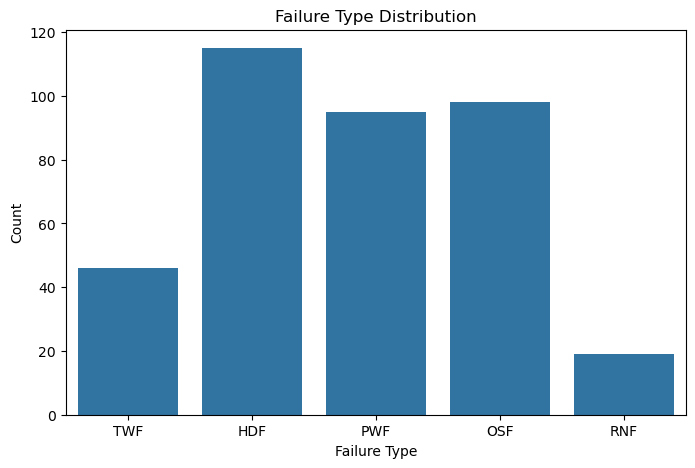

In [10]:
# Visualize failure type counts

failure_counts = df[failure_types].sum()

plt.figure()

sns.barplot(x=failure_counts.index, y=failure_counts.values)

plt.title("Failure Type Distribution")
plt.xlabel("Failure Type")
plt.ylabel("Count")

# Save visualization
plt.savefig(PROJECT_ROOT / "visuals" / "failure_type_distribution.png", bbox_inches="tight")

plt.show()

## Sensor Variable Distributions

The predictive maintenance dataset contains several sensor measurements that describe machine operating conditions.

These include:

- Air Temperature
- Process Temperature
- Rotational Speed
- Torque
- Tool Wear

Analyzing their distributions helps identify patterns, skewness, and possible anomalies that may influence machine failure.

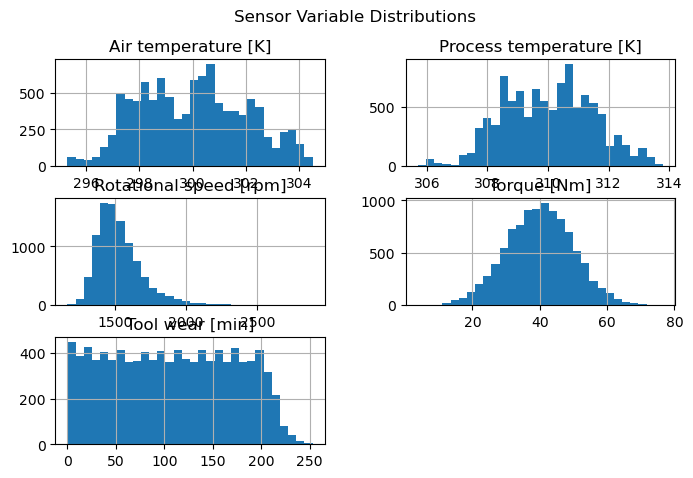

In [11]:
# Select numerical sensor variables
sensor_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Plot histograms for each sensor feature
df[sensor_features].hist(bins=30)

plt.suptitle("Sensor Variable Distributions")

# Save visualization
plt.savefig(PROJECT_ROOT / "visuals" / "sensor_feature_distributions.png", bbox_inches="tight")

plt.show()

## Outlier Analysis

Outliers represent unusually high or low sensor readings that differ significantly from the majority of observations.

In predictive maintenance datasets, outliers can be important because extreme sensor values may indicate abnormal machine behavior or impending failure.

Boxplots are used here to visually identify potential outliers in the key sensor variables.

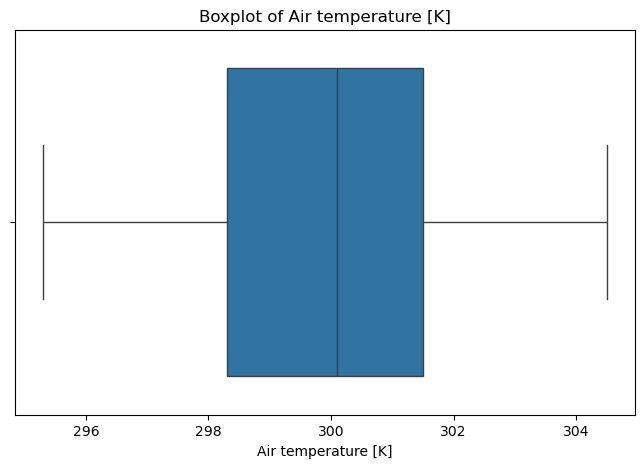

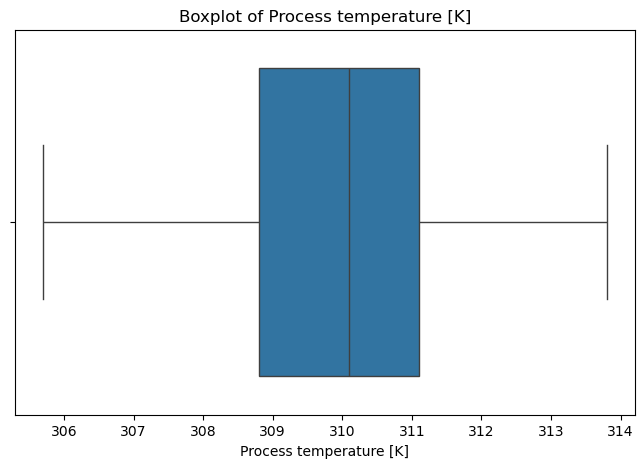

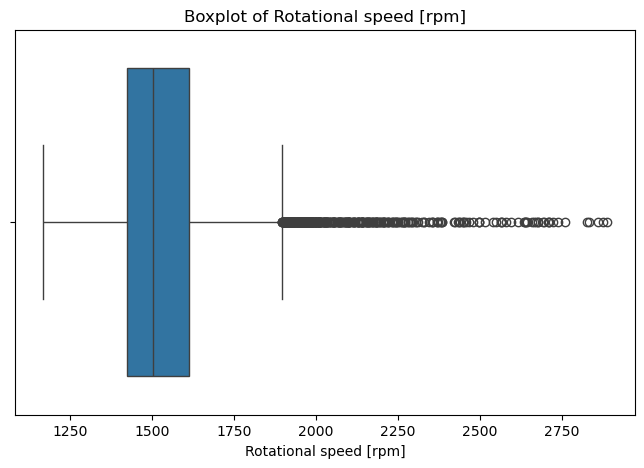

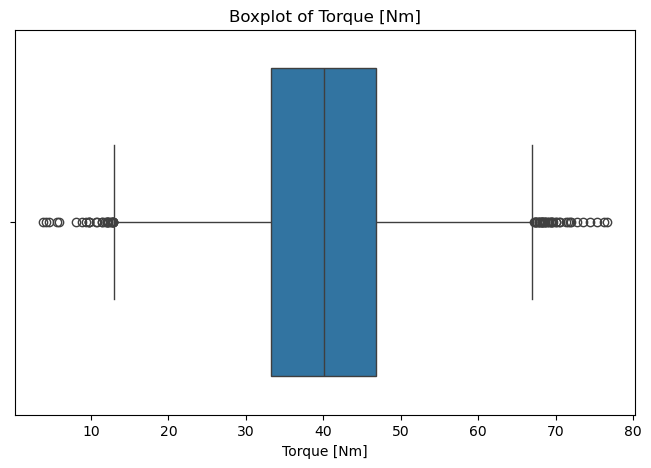

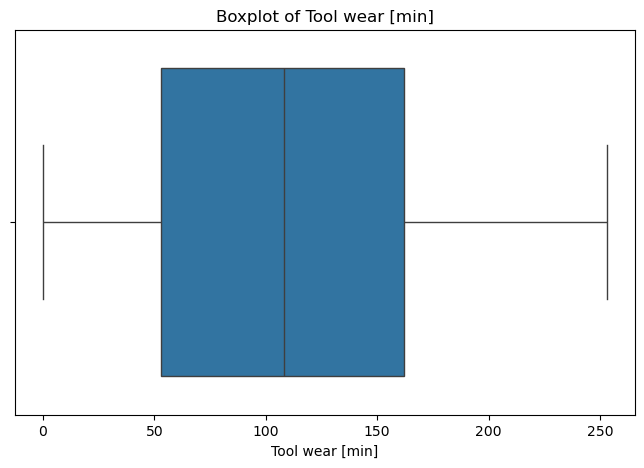

In [12]:
# Generate boxplots for sensor variables to detect outliers

for feature in sensor_features:

    plt.figure()

    sns.boxplot(x=df[feature])

    plt.title(f"Boxplot of {feature}")
    plt.xlabel(feature)

    # Create a safe file name for saving the plot
    safe_name = feature.lower().replace(" ", "_").replace("[", "").replace("]", "").replace("/", "_")

    # Save visualization
    plt.savefig(PROJECT_ROOT / "visuals" / f"{safe_name}_boxplot.png", bbox_inches="tight")

    plt.show()

## Correlation Analysis

Correlation analysis measures the strength and direction of relationships between numerical variables.

A correlation heatmap helps identify:

- Strong relationships between sensor variables
- Potential multicollinearity between features
- Variables that may influence machine failure

Understanding these relationships helps guide feature selection and model development.

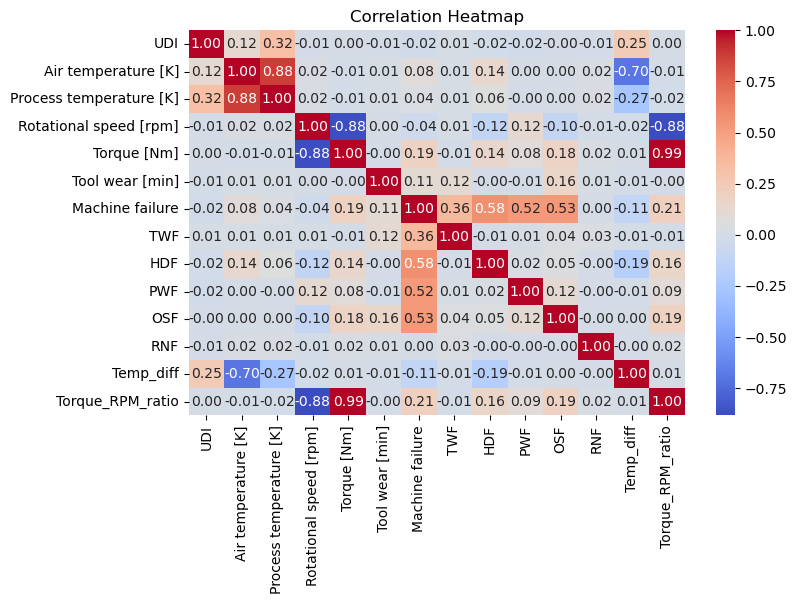

In [13]:
# Select numerical columns for correlation analysis
numerical_features = df.select_dtypes(include=["int64", "float64"])

# Compute correlation matrix
corr_matrix = numerical_features.corr()

# Plot correlation heatmap
plt.figure()

sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")

# Save visualization
plt.savefig(PROJECT_ROOT / "visuals" / "correlation_heatmap.png", bbox_inches="tight")

plt.show()

## Sensor Features vs Machine Failure

In this section, we examine how key sensor variables differ between machines that failed and those that did not fail.

By comparing sensor measurements across the failure classes, we can identify patterns that may indicate higher risk of machine breakdown.

This analysis helps determine which variables may be strong predictors of machine failure and will guide the feature importance analysis during model training.

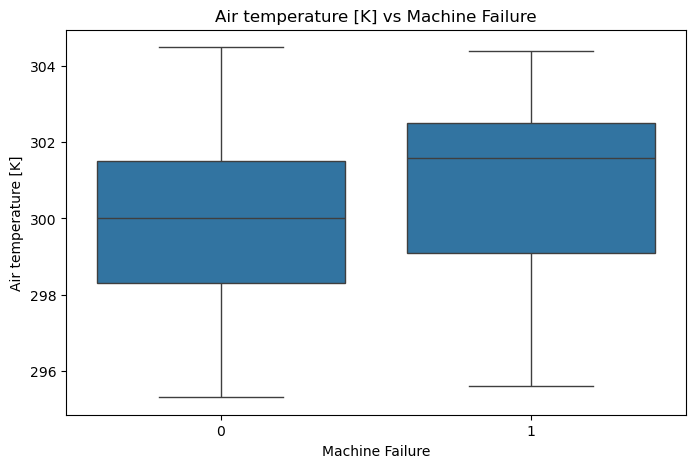

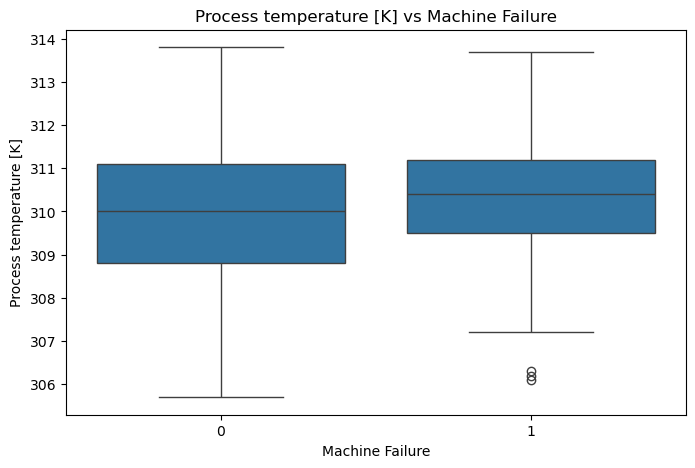

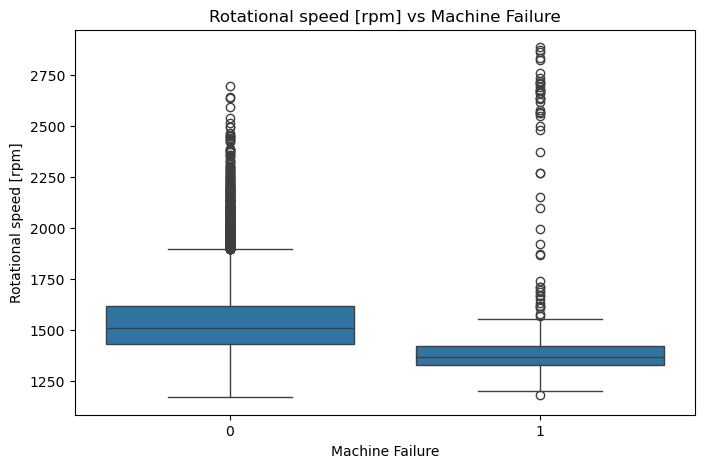

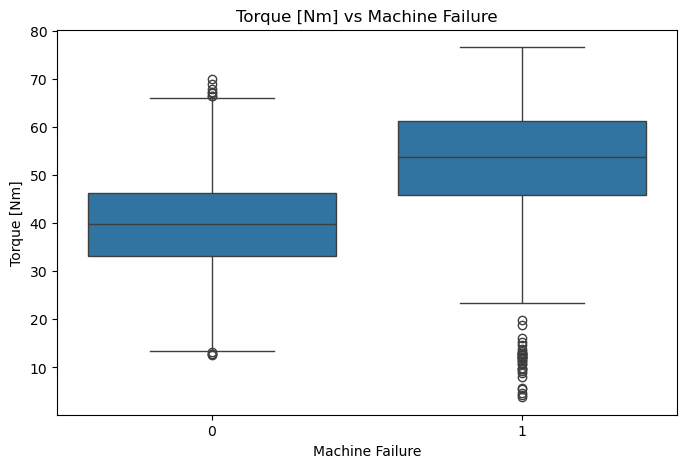

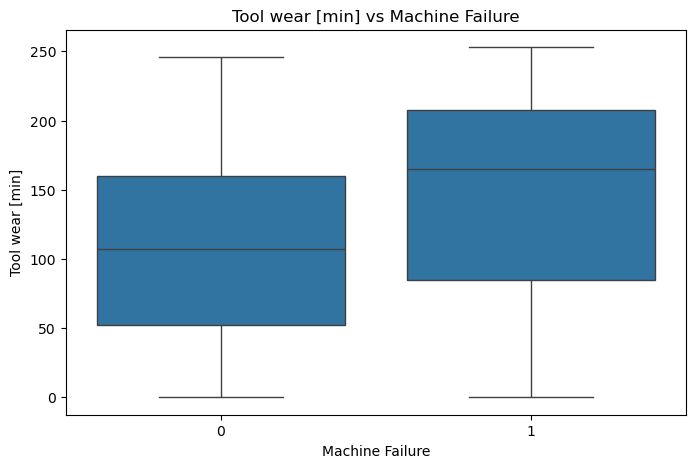

In [14]:
# Compare sensor variables against machine failure using boxplots

for feature in sensor_features:

    plt.figure()

    sns.boxplot(x="Machine failure", y=feature, data=df)

    plt.title(f"{feature} vs Machine Failure")
    plt.xlabel("Machine Failure")
    plt.ylabel(feature)

    # Create safe filename
    safe_name = feature.lower().replace(" ", "_").replace("[", "").replace("]", "").replace("/", "_")

    # Save visualization
    plt.savefig(PROJECT_ROOT / "visuals" / f"{safe_name}_vs_machine_failure.png", bbox_inches="tight")

    plt.show()

## Machine Type vs Machine Failure

Machines in the dataset are categorized into three types:

- L – Low
- M – Medium
- H – High

Analyzing the relationship between machine type and machine failure helps determine whether certain machine categories are more prone to breakdown.

This information can provide operational insights into machine reliability across different machine types.

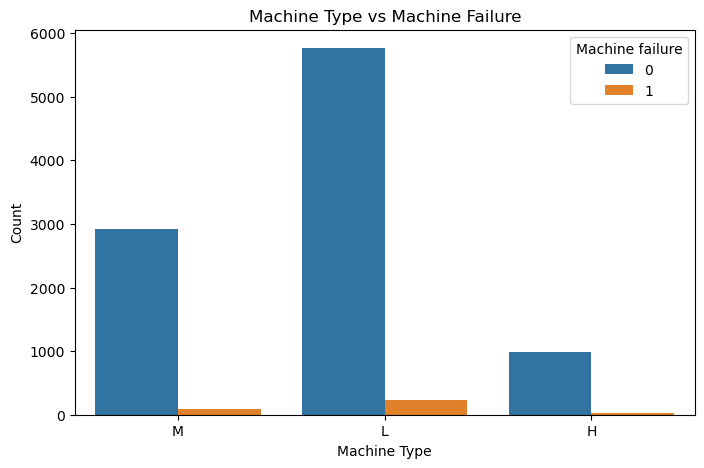

In [15]:
# Analyze the relationship between machine type and machine failure

plt.figure()

sns.countplot(x="Type", hue="Machine failure", data=df)

plt.title("Machine Type vs Machine Failure")
plt.xlabel("Machine Type")
plt.ylabel("Count")

# Save visualization
plt.savefig(PROJECT_ROOT / "visuals" / "machine_type_vs_machine_failure.png", bbox_inches="tight")

plt.show()

## Key Insights from Exploratory Data Analysis

The exploratory data analysis provided several important observations about the predictive maintenance dataset.

### Dataset Structure
The dataset contains sensor measurements describing machine operating conditions along with indicators of machine failure and specific failure types. Feature engineering was applied successfully, and the dataset was verified to contain the expected variables.

### Missing Values
No significant missing values were detected in the dataset, indicating that the data is complete and suitable for modeling without additional imputation.

### Target Variable Distribution
The distribution of the target variable shows that machine failures occur much less frequently than normal operations. This indicates a class imbalance, which is common in predictive maintenance problems.

### Failure Type Patterns
Different types of mechanical failures such as tool wear failure, heat dissipation failure, power failure, overstrain failure, and random failure were analyzed. These failure indicators provide deeper insights into the underlying causes of machine breakdowns.

### Sensor Variable Behavior
The distribution of key sensor variables such as air temperature, process temperature, rotational speed, torque, and tool wear reveals typical operating ranges and potential extreme values.

### Outlier Detection
Boxplots identified several extreme values in sensor readings. In predictive maintenance contexts, these extreme values may represent abnormal machine behavior and could be related to failure events.

### Feature Relationships
Correlation analysis showed relationships among sensor variables. Some variables may share strong correlations, which is useful to consider when selecting features for predictive modeling.

### Sensor Variables and Failure
Comparing sensor readings between failed and non-failed machines suggests that certain variables such as torque and tool wear may have stronger associations with machine failure.

### Machine Type Differences
Machines categorized as Low (L), Medium (M), and High (H) types show different distributions of failure occurrences, indicating that machine category may influence reliability patterns.

### Conclusion
The insights from this exploratory analysis provide a strong foundation for the next stage of the project, which involves feature selection, predictive modeling, and risk tier classification for machine failure prediction.

## Overall EDA Conclusions

Exploratory analysis indicates that machine failure is strongly associated with operational stress indicators such as torque, tool wear, and rotational speed. While individual linear correlations with failure are modest, distributional differences between failure and non-failure cases suggest meaningful non-linear relationships. Observed patterns reflect genuine operating behavior rather than data quality issues, and therefore no aggressive outlier removal is justified prior to modeling.
